In [1]:
from pathlib import Path
import gzip
import hashlib
import json
import platform
import struct
import time
import warnings
from importlib.metadata import version

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, log_loss
from threadpoolctl import threadpool_limits

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists() and (p / "notebooks").is_dir())
RAW = ROOT / "data" / "raw"
SPLITS = ROOT / "data" / "splits"
RESULTS = ROOT / "results" / "logistic-regression-regularization"
RESULTS.mkdir(parents=True, exist_ok=True)
SEED = 42
CLASS_NAMES = np.array(["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
environment = {"python": platform.python_version(), **{name: version(name) for name in ("numpy", "pandas", "scikit-learn", "joblib", "threadpoolctl")}}
display(pd.Series(environment, name="Version"))

python           3.12.0
numpy             2.5.4
pandas            3.0.6
scikit-learn      1.9.1
joblib            1.6.0
threadpoolctl     3.7.0
Name: Version, dtype: str

In [2]:
def read_idx(path):
    with gzip.open(path, "rb") as stream:
        payload = stream.read()
    zero_a, zero_b, dtype_code, dimensions = struct.unpack(">BBBB", payload[:4])
    if (zero_a, zero_b, dtype_code) != (0, 0, 8) or dimensions not in (1, 3):
        raise ValueError(f"Invalid IDX header: {path.name}")
    offset = 4 + 4 * dimensions
    shape = struct.unpack(">" + "I" * dimensions, payload[4:offset])
    values = np.frombuffer(payload, dtype=np.uint8, offset=offset)
    if values.size != np.prod(shape):
        raise ValueError(f"Invalid IDX payload size: {path.name}")
    return values.reshape(shape)

metadata_path = SPLITS / "train-validation-v1.json"
split_path = SPLITS / "train-validation-v1.npz"
if not metadata_path.exists() or not split_path.exists():
    raise FileNotFoundError("Run 01-data-exploration.ipynb first")
split_metadata = json.loads(metadata_path.read_text())
split_sha256 = hashlib.sha256(split_path.read_bytes()).hexdigest()
assert split_sha256 == split_metadata["split_file_sha256"]
training_files = [record for record in split_metadata["files"] if record["filename"].startswith("train-")]
for record in training_files:
    assert hashlib.sha256((RAW / record["filename"]).read_bytes()).hexdigest() == record["sha256"]
images = read_idx(RAW / "train-images-idx3-ubyte.gz")
labels = read_idx(RAW / "train-labels-idx1-ubyte.gz")
with np.load(split_path, allow_pickle=False) as saved:
    train_indices = saved["train_indices"]
    validation_indices = saved["validation_indices"]
assert images.shape == (60000, 28, 28) and labels.shape == (60000,)
assert np.array_equal(np.sort(np.concatenate([train_indices, validation_indices])), np.arange(len(labels)))
assert np.intersect1d(train_indices, validation_indices).size == 0
X_train = images[train_indices].reshape(len(train_indices), -1).astype(np.float64) / 255.0
X_validation = images[validation_indices].reshape(len(validation_indices), -1).astype(np.float64) / 255.0
y_train = labels[train_indices]
y_validation = labels[validation_indices]
assert np.isfinite(X_train).all() and np.isfinite(X_validation).all()
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_validation.min() <= X_validation.max() <= 1
display(pd.DataFrame({"split": ["Training", "Validation"], "images": [len(y_train), len(y_validation)], "features": [X_train.shape[1], X_validation.shape[1]]}))

,split,images,features
0,Training,48000,784
1,Validation,12000,784


In [3]:
C_VALUES = [0.01, 0.1, 1.0, 10.0]
COMMON_PARAMETERS = {"l1_ratio": 0.0, "solver": "lbfgs", "max_iter": 2000, "tol": 1e-4, "random_state": SEED}
models = {}
rows = []
for c_value in C_VALUES:
    candidate = LogisticRegression(C=c_value, **COMMON_PARAMETERS)
    start = time.perf_counter()
    with threadpool_limits(limits=4), warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", ConvergenceWarning)
        candidate.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    convergence_messages = [str(w.message) for w in captured if issubclass(w.category, ConvergenceWarning)]
    for warning in captured:
        if not issubclass(warning.category, ConvergenceWarning):
            warnings.warn(str(warning.message), warning.category)
    with threadpool_limits(limits=4):
        train_pred = candidate.predict(X_train)
        validation_pred = candidate.predict(X_validation)
    report = classification_report(y_validation, validation_pred, labels=np.arange(10), output_dict=True, zero_division=0)
    row = {"C": c_value, "train_accuracy": accuracy_score(y_train, train_pred),
           "validation_accuracy": accuracy_score(y_validation, validation_pred),
           "train_macro_f1": f1_score(y_train, train_pred, average="macro"),
           "validation_macro_f1": f1_score(y_validation, validation_pred, average="macro"),
           "shirt_recall": report["6"]["recall"], "iterations": int(candidate.n_iter_.max()),
           "fit_seconds": fit_seconds, "converged": len(convergence_messages) == 0,
           "convergence_messages": convergence_messages}
    row["accuracy_gap"] = row["train_accuracy"] - row["validation_accuracy"]
    rows.append(row)
    models[c_value] = candidate
    pd.DataFrame(rows).to_json(RESULTS / "search-progress.json", orient="records", indent=2)
    print(f"C={c_value:g}: validation accuracy={row['validation_accuracy']:.4f}, macro-F1={row['validation_macro_f1']:.4f}, converged={row['converged']}")
comparison = pd.DataFrame(rows)
display(comparison.drop(columns="convergence_messages").round(4))
if not comparison.converged.all():
    raise RuntimeError("Resolve convergence warnings before selecting a candidate")

C=0.01: validation accuracy=0.8484, macro-F1=0.8472, converged=True


C=0.1: validation accuracy=0.8540, macro-F1=0.8530, converged=True


C=1: validation accuracy=0.8532, macro-F1=0.8523, converged=True


C=10: validation accuracy=0.8458, macro-F1=0.8449, converged=True


,C,train_accuracy,validation_accuracy,train_macro_f1,validation_macro_f1,shirt_recall,iterations,fit_seconds,converged,accuracy_gap
0,0.01,0.8569,0.8484,0.8560,0.8472,0.5775,186,6.2554,True,0.0085
1,0.10,0.8742,0.8540,0.8735,0.8530,0.5942,299,9.9449,True,0.0202
2,1.00,0.8843,0.8532,0.8836,0.8523,0.5900,603,20.1985,True,0.0311
3,10.00,0.8889,0.8458,0.8882,0.8449,0.5817,1072,36.1289,True,0.0430


In [4]:
ranking = comparison.sort_values(["validation_accuracy", "C"], ascending=[False, True])
best_c = float(ranking.iloc[0]["C"])
best_model = models[best_c]
baseline_row = comparison.loc[comparison.C == 1.0].iloc[0]
best_row = ranking.iloc[0]
print(f"Selected C: {best_c:g}")
print(f"Validation accuracy change from C=1: {100 * (best_row.validation_accuracy - baseline_row.validation_accuracy):+.3f} percentage points")
print(f"Validation macro-F1 change from C=1: {best_row.validation_macro_f1 - baseline_row.validation_macro_f1:+.4f}")
print(f"Shirt recall change from C=1: {100 * (best_row.shirt_recall - baseline_row.shirt_recall):+.3f} percentage points")
with threadpool_limits(limits=4):
    selected_predictions = best_model.predict(X_validation)
selected_report = classification_report(y_validation, selected_predictions, labels=np.arange(10), target_names=CLASS_NAMES.tolist(), output_dict=True, zero_division=0)
per_class = pd.DataFrame({name: selected_report[name] for name in CLASS_NAMES}).T
per_class["support"] = per_class["support"].astype(int)
display(per_class.round(4))

Selected C: 0.1
Validation accuracy change from C=1: +0.083 percentage points
Validation macro-F1 change from C=1: +0.0007
Shirt recall change from C=1: +0.417 percentage points


,precision,recall,f1-score,support
T-shirt/top,0.7888,0.8000,0.7944,1200
Trouser,0.9766,0.9725,0.9745,1200
Pullover,0.7566,0.7592,0.7579,1200
Dress,0.8631,0.8825,0.8727,1200
Coat,0.7634,0.7933,0.7781,1200
Sandal,0.9313,0.9258,0.9285,1200
Shirt,0.6590,0.5942,0.6249,1200
Sneaker,0.9050,0.9208,0.9128,1200
Bag,0.9347,0.9542,0.9443,1200
Ankle boot,0.9462,0.9375,0.9418,1200


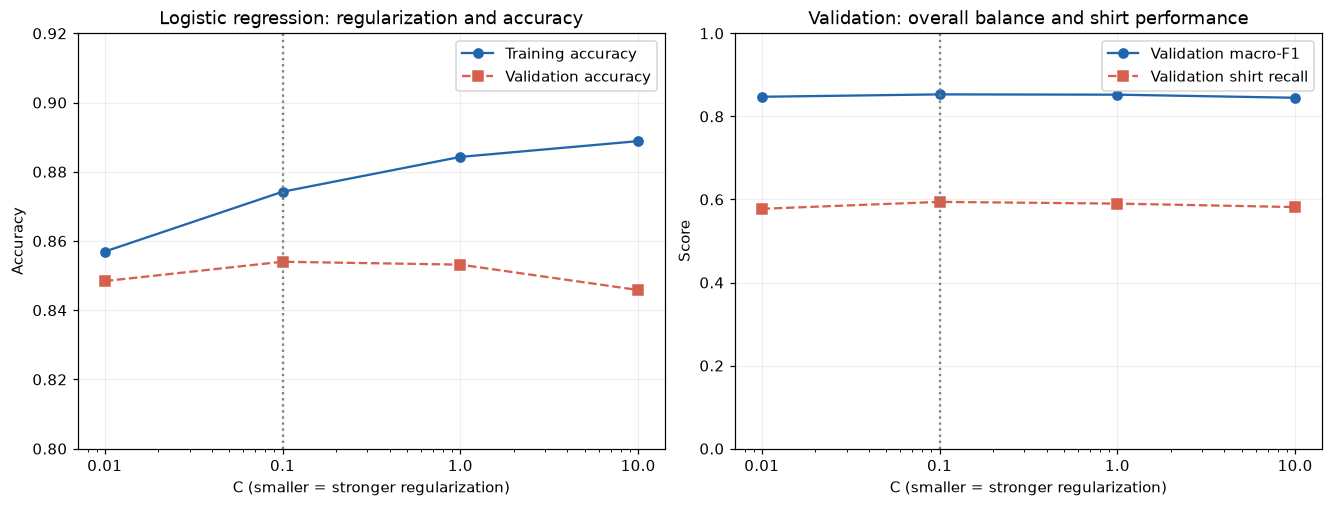

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
axes[0].plot(comparison.C, comparison.train_accuracy, "o-", label="Training accuracy", color="#2166ac")
axes[0].plot(comparison.C, comparison.validation_accuracy, "s--", label="Validation accuracy", color="#d6604d")
axes[0].set(title="Logistic regression: regularization and accuracy", xlabel="C (smaller = stronger regularization)", ylabel="Accuracy", xscale="log", ylim=(0.80, 0.92))
axes[0].legend()
axes[1].plot(comparison.C, comparison.validation_macro_f1, "o-", label="Validation macro-F1", color="#2166ac")
axes[1].plot(comparison.C, comparison.shirt_recall, "s--", label="Validation shirt recall", color="#d6604d")
axes[1].set(title="Validation: overall balance and shirt performance", xlabel="C (smaller = stronger regularization)", ylabel="Score", xscale="log", ylim=(0, 1))
axes[1].legend()
for ax in axes:
    ax.axvline(best_c, color="gray", linestyle=":", label="Selected C")
    ax.set_xticks(C_VALUES, labels=[str(c) for c in C_VALUES])
    ax.grid(alpha=0.2)
fig.savefig(RESULTS / "regularization-comparison.png", bbox_inches="tight")
plt.show()

In [6]:
model_path = RESULTS / "selected-model.joblib"
joblib.dump(best_model, model_path)
with threadpool_limits(limits=4):
    np.testing.assert_array_equal(joblib.load(model_path).predict(X_validation), selected_predictions)
comparison.to_csv(RESULTS / "comparison.csv", index=False)
per_class.to_csv(RESULTS / "selected-validation-classification-report.csv")
pd.DataFrame({"source_index": validation_indices, "actual": y_validation, "predicted": selected_predictions}).to_csv(RESULTS / "selected-validation-predictions.csv", index=False)
metadata = {
    "C_values": C_VALUES, "common_parameters": COMMON_PARAMETERS,
    "selection_rule": "Highest validation accuracy; exact ties prefer smaller C",
    "selected_C": best_c, "split_sha256": split_sha256, "environment": environment,
    "source_files": training_files, "preprocessing": "float64 pixels / 255, flatten in C order",
    "training_count": len(y_train), "validation_count": len(y_validation), "test_evaluated": False,
    "comparisons": rows, "model_sha256": hashlib.sha256(model_path.read_bytes()).hexdigest(),
}
(RESULTS / "run-metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print("Saved results/logistic-regression-regularization artifacts")
print("Reloaded selected model reproduces all validation predictions")

Saved results/logistic-regression-regularization artifacts
Reloaded selected model reproduces all validation predictions
